# Лабораторная работа №1
## Метод k ближайших соседей

В этой работе я исследую KNN на двух задачах: определение статуса кредитной заявки
и прогноз прочности бетона. Сначала обучу готовые модели из sklearn, затем попробую
улучшить их качество и сравню результат со своей реализацией алгоритма.

| Задача | Данные | Что предсказываю | Основная метрика |
|:--|:--|:--|:--|
| Классификация | Loan Approval, 45 000 заявок | Одобрение заявки | F1 ↑ |
| Регрессия | Concrete Strength, 1030 измерений | Прочность бетона, МПа | MAE ↓ |

**Ход работы:** выбор данных → исходные модели → проверка гипотез → своя реализация → выводы.

---

## 1. Данные и постановка задачи

### Классификация: одобрение кредита

Для классификации я выбрал [Loan Approval Classification Data](https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data).
Практический смысл задачи — предварительно оценить, будет ли одобрена заявка по данным клиента.
Целевая переменная `loan_status` принимает значения 1 — одобрено и 0 — отказ.

В данных есть числовые и категориальные признаки, поэтому можно проверить, как KNN
реагирует на разные масштабы и кодирование категорий. Из признаков исключаю `loan_int_rate`:
в моей постановке прогноз нужен до назначения процентной ставки. Остальные сведения
о клиенте и запрашиваемой сумме считаю известными на момент подачи заявки.

Набор синтетический и, по описанию автора, расширен с помощью SMOTENC. Это нужно
учитывать при выводах: хорошее качество на этих данных ещё не означает такое же качество
на реальных банковских заявках. Кроме того, я предсказываю одобрение, а не будущий дефолт.

### Регрессия: прочность бетона

Для регрессии использую [Concrete Compressive Strength из UCI](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength).
По количеству семи компонентов смеси и возрасту образца нужно предсказать прочность
при сжатии — `strength`, в МПа. Такой прогноз может помочь при выборе состава
и планировании испытаний материала.

### Как оцениваю качество

Для классификации основной метрикой выбрал **F1 класса 1**. Она учитывает и precision,
и recall, что полезно при неодинаковой численности классов. Дополнительно смотрю accuracy,
balanced accuracy, ROC-AUC и average precision, чтобы оценка не зависела от одной метрики.

Для регрессии основной показатель — **MAE**: его удобно понимать как среднюю абсолютную
ошибку в МПа. Также считаю RMSE, которая сильнее учитывает крупные промахи, и R².

### Разделение данных

Кредитные заявки разделяю на train и test в пропорции 80/20 со стратификацией.
Для подбора параметров использую три стратифицированных фолда и `random_state=42`.

Для бетона сначала удаляю полные дубликаты. Затем объединяю измерения с одинаковыми
семью компонентами в одну рецептуру. Возраст и прочность в это определение не входят.
Разделяю данные по рецептурам через GroupShuffleSplit, а для CV использую GroupKFold(3).
Так одна смесь в разном возрасте не попадёт одновременно в обучение и проверку.

Распределения изучаю только на train. Заполнение пропусков, масштабирование и кодирование
объединяю в Pipeline, чтобы они обучались заново внутри каждого фолда.
Test оставляю для оценки после выбора параметров.

### Какие признаки используются

В кредитном наборе 45 000 строк и 14 столбцов. После исключения цели и ставки остаётся
12 входных признаков: 7 числовых и 5 категориальных.

| Признак | Смысл |
|:--|:--|
| `person_age` | Возраст клиента, годы |
| `person_gender` | Пол |
| `person_education` | Уровень образования |
| `person_income` | Годовой доход |
| `person_emp_exp` | Стаж работы, годы |
| `person_home_ownership` | Тип владения жильём |
| `loan_amnt` | Запрашиваемая сумма кредита |
| `loan_intent` | Цель кредита |
| `loan_percent_income` | Отношение суммы кредита к доходу |
| `cb_person_cred_hist_length` | Длительность кредитной истории, годы |
| `credit_score` | Кредитный рейтинг |
| `previous_loan_defaults_on_file` | Наличие прошлых дефолтов |
| `loan_int_rate` | Процентная ставка; исключаю из входов |
| `loan_status` | Цель: 1 — одобрено, 0 — отказ |

Единицы дохода и суммы кредита в доступном описании отдельно не уточняются,
поэтому трактую их как денежные величины в одной шкале.

В наборе бетона 1030 строк, 8 входных признаков и одна целевая переменная.

| Признак | Смысл | Единицы |
|:--|:--|:--|
| `cement` | Цемент | кг/м³ |
| `slag` | Доменный шлак | кг/м³ |
| `fly_ash` | Зола-унос | кг/м³ |
| `water` | Вода | кг/м³ |
| `superplasticizer` | Суперпластификатор | кг/м³ |
| `coarse_aggregate` | Крупный заполнитель | кг/м³ |
| `fine_aggregate` | Мелкий заполнитель | кг/м³ |
| `age` | Возраст образца | дни |
| `strength` | Цель: прочность при сжатии | МПа |

Оба исходных набора не содержат пропусков. Заполнение пропусков всё равно включаю
в Pipeline как часть подготовки. После удаления 25 полных дубликатов бетона
остаётся 1005 измерений: **799 строк и 342 рецептуры в train**, **206 строк и 86 рецептур в test**.
Кредитный набор не содержит полных дубликатов; train/test — **36 000 / 9 000** строк.


### Как понимать метрики

Основные показатели считаю по формулам:

$$F_1=\frac{2TP}{2TP+FP+FN},\qquad
  MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|.$$

Здесь TP — правильно предсказанные одобрения, FP — ошибочные одобрения,
FN — пропущенные одобрения. В кредитных данных класс 1 составляет около 22,2%,
поэтому одной accuracy недостаточно. F1 помогает одновременно учитывать точность и полноту,
а MAE показывает ошибку прочности в понятных единицах — МПа.

| Дополнительная метрика | Что показывает |
|:--|:--|
| Precision | Какая доля предсказанных одобрений действительно относится к классу 1 |
| Recall | Какая доля реальных одобрений найдена моделью |
| Accuracy | Доля правильных ответов среди всех заявок |
| Balanced accuracy | Средняя полнота по двум классам, с одинаковым вкладом каждого класса |
| ROC-AUC | Насколько хорошо вероятности ранжируют классы при разных порогах; случайный ориентир — 0,5 |
| Average precision (AP) | Качество ранжирования через precision и recall; ориентир случайного ранжирования — доля класса 1 |
| RMSE | Корень средней квадратичной ошибки в МПа; сильнее реагирует на крупные промахи |
| R² | $1-\sum(y_i-\hat y_i)^2/\sum(y_i-\bar y)^2$; сравнение с постоянным прогнозом среднего, может быть отрицательным |

В сравнении разных алгоритмов для одной задачи использую один и тот же набор метрик.
F1 и ошибки прочности между собой не складываю: они относятся к разным задачам.


### Источники и выбор данных

Автор кредитного набора — **taweilo**,
[страница Loan Approval на Kaggle](https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data).
В работе использую CSV из [публичной копии с фиксированным commit](https://github.com/dpidaparthi/loan-approval-classification/blob/379a24f61cd5d9f032415b14a5797f30cf1d4a05/data/loan_data.csv).
Побайтовое совпадение с загрузкой Kaggle не проверено: контрольная сумма в коде относится
к этой копии. По описанию автора набор синтетический, с расширением SMOTENC.
Условия использования задаются источником Kaggle; отдельную лицензию на данные я не назначаю.

Набор бетона: **Yeh, I. (1998), Concrete Compressive Strength**,
[UCI №165, DOI 10.24432/C5PK67](https://doi.org/10.24432/C5PK67).
Использую исходный XLS из [официального архива UCI](https://archive.ics.uci.edu/static/public/165/concrete+compressive+strength.zip),
лицензия — [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

При подготовке первой работы выбор сверялся с
[таблицей группы](https://docs.google.com/spreadsheets/d/1szg1vYr3MLq8eqCejGbvVOdF7t87slb3h2x8qv2e-So/edit?gid=0)
**10 ноября 2026 года**. В сохранённой проверке учтено 20 записей,
совпадений выбранных наборов с другими студентами не найдено.
Это результат сверки на указанную дату, а не повторная проверка текущего состояния таблицы.


### Подключение библиотек

Подключу библиотеки для работы с данными, обучения и графиков. Зафиксирую число потоков,
чтобы измерения времени обучения и предсказания были более сопоставимы.

In [1]:
# Все вычисления выполняются Python из lab_1/.venv; ограничиваем параллелизм.
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ.setdefault("MPLCONFIGDIR", "/tmp/vkr_matplotlib")
import sys
import json
import platform
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GroupShuffleSplit, GroupKFold, cross_val_score, GridSearchCV
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
LAB = Path.cwd() if (Path.cwd() / "data" / "raw" / "loan_data.csv").exists() else Path.cwd() / "lab_1"
sys.path.insert(0, str(LAB))
thread_limit = threadpool_limits(limits=1)
sns.set_theme(style="whitegrid")
RESULTS = LAB / "results"
RESULTS.mkdir(exist_ok=True)
print({"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__})

# Общий стиль таблиц и графиков.
MODEL_NAMES = {
    "sklearn_baseline": "sklearn · исходная",
    "sklearn_improved": "sklearn · улучшенная",
    "custom_baseline": "своя · исходная",
    "custom_improved": "своя · улучшенная",
    "dummy": "Dummy",
}
TASK_NAMES = {"classification": "Классификация", "regression": "Регрессия"}
COLUMN_NAMES = {
    "model": "Модель", "task": "Задача", "lab": "Работа", "dataset": "Набор данных",
    "algorithm": "Алгоритм", "implementation": "Реализация", "stage": "Вариант",
    "f1": "F1 ↑", "precision": "Precision", "recall": "Recall",
    "accuracy": "Accuracy", "balanced_accuracy": "Balanced accuracy",
    "roc_auc": "ROC-AUC", "average_precision": "AP", "mae": "MAE, МПа ↓",
    "rmse": "RMSE, МПа ↓", "r2": "R² ↑", "fit_seconds": "Обучение, с",
    "predict_seconds": "Прогноз, с", "mode": "Признаки", "representation": "Признаки",
    "cv_mean": "Среднее CV", "cv_std": "Разброс CV", "mean_test_score": "Среднее CV",
    "std_test_score": "Разброс CV", "rank_test_score": "Место", "status": "Статус",
    "comparison": "Сравнение", "delta": "Изменение", "metric": "Метрика",
    "estimator": "Алгоритм", "n_iter": "Итерации", "gradient_norm": "Норма градиента",
    "objective": "Функция потерь", "missing_train": "Пропуски", "dtype": "Тип",
    "missing": "Пропуски", "unique": "Уникальные", "type": "Тип",
    "param_model__n_neighbors": "Соседи (k)", "param_model__weights": "Веса",
    "param_model__p": "Расстояние (p)", "class_weight": "Веса классов",
    "count": "Количество", "fraction": "Доля", "train_fraction": "Доля в train",
}

def show_table(value, title=None):
    """Вывод таблицы с подписями и одинаковой точностью чисел."""
    if isinstance(value, pd.Series):
        value = value.to_frame()
    if not isinstance(value, pd.DataFrame):
        display(value)
        return
    table = value.copy()
    for column in table.columns:
        table[column] = table[column].map(
            lambda item: MODEL_NAMES.get(item, TASK_NAMES.get(item, item)) if isinstance(item, str) else item)
    table = table.rename(columns=COLUMN_NAMES)
    styled = table.style.format(precision=4, na_rep="—").set_table_styles([
        {"selector": "th", "props": [("background-color", "#edf3f8"), ("color", "#243b53"),
                                     ("padding", "9px 12px"), ("text-align", "left")]},
        {"selector": "td", "props": [("padding", "7px 12px"), ("border-bottom", "1px solid #e8edf2")]},
        {"selector": "caption", "props": [("caption-side", "top"), ("text-align", "left"),
                                          ("font-weight", "600"), ("padding", "10px 0")]},
    ])
    if isinstance(table.index, pd.RangeIndex):
        styled = styled.hide(axis="index")
    if title:
        styled = styled.set_caption(title)
    if "Норма градиента" in table.columns:
        styled = styled.format({"Норма градиента": "{:.2e}"})
    display(styled)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "grid.alpha": 0.25, "axes.prop_cycle": plt.cycler(color=["#387ca3", "#db9655", "#4c9c8a", "#9c7cb5"]),
})

{'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.1.1', 'sklearn': '1.9.1'}


### Функции чтения данных, признаков и метрик

Задам имена столбцов, цели и контрольные суммы. Здесь же приведу функции чтения,
расчёта метрик и создания новых признаков, чтобы их можно было посмотреть прямо в работе.
Для отношений использую исходные значения до log1p; небольшое ограничение знаменателя
защищает от деления на ноль.

In [2]:
# Общие функции эксперимента.
"""Два датасета, общий протокол, признаки и метрики лабораторной №1."""

import hashlib

from pathlib import Path

import warnings

import numpy as np

import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin

from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             average_precision_score, mean_absolute_error,
                             root_mean_squared_error, r2_score)

SEED = 42

CATEGORICAL = ["person_gender", "person_education", "person_home_ownership",
               "loan_intent", "previous_loan_defaults_on_file"]

CONCRETE_COLUMNS = ["cement", "slag", "fly_ash", "water", "superplasticizer",
                    "coarse_aggregate", "fine_aggregate", "age", "strength"]

DATASETS = {
    "classification": {
        "name": "Loan Approval Classification Data", "file": "loan_data.csv",
        "sha256": "67cca604cd71cbd605014f721d078d20d44d726d625945591450733535f9868a",
        "target": "loan_status", "excluded": ["loan_status", "loan_int_rate"],
        "protocol_id": "loan-v1-seed42-test20", "expected_shape": (45000, 14),
    },
    "regression": {
        "name": "Concrete Compressive Strength", "file": "Concrete_Data.xls",
        "sha256": "710076c66b9ca3f8050e7942f3dcbdbe04013534daeb0077ffd3079a52d8e0c4",
        "target": "strength", "excluded": ["strength"],
        "protocol_id": "concrete-v1-recipe-groups-seed42-test20", "expected_shape": (1030, 9),
    },
}

EXCLUDED = {task: spec["excluded"] for task, spec in DATASETS.items()}

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def load_dataset(lab, task):
    """Чтение исходного файла с проверкой SHA256; y не меняется."""
    spec = DATASETS[task]
    path = Path(lab) / "data" / "raw" / spec["file"]
    if sha256(path) != spec["sha256"]:
        raise ValueError(f"Контрольная сумма {path.name} не совпала")
    if task == "classification":
        frame = pd.read_csv(path)
    else:
        # Подавляем только сообщение о будущем удалении xlrd из pandas, не ошибки данных.
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="The xlrd engine is deprecated.*")
            frame = pd.read_excel(path, engine="xlrd")
        frame.columns = CONCRETE_COLUMNS
    if frame.shape != spec["expected_shape"]:
        raise ValueError(f"Неожиданная форма {path.name}: {frame.shape}")
    return frame

class TaskFeatures(TransformerMixin, BaseEstimator):
    """Детерминированные признаки: не используют y и статистики test."""
    def __init__(self, task="classification", mode="raw"):
        self.task = task
        self.mode = mode

    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        result = X.copy()
        if self.mode in ("log", "engineered"):
            column = "person_income" if self.task == "classification" else "age"
            result[column] = np.log1p(result[column].clip(lower=0))
        if self.mode == "engineered":
            if self.task == "classification":
                result["employment_age_ratio"] = X["person_emp_exp"] / X["person_age"].clip(lower=1)
                result["credit_history_age_ratio"] = X["cb_person_cred_hist_length"] / X["person_age"].clip(lower=1)
            else:
                binder = (X["cement"] + X["slag"] + X["fly_ash"]).clip(lower=1e-12)
                result["binder"] = binder
                result["water_binder_ratio"] = X["water"] / binder
                result["aggregate_binder_ratio"] = (X["coarse_aggregate"] + X["fine_aggregate"]) / binder
        return result

def evaluate(task, truth, prediction, probabilities=None):
    if task == "classification":
        return {
            "f1": f1_score(truth, prediction, zero_division=0),
            "precision": precision_score(truth, prediction, zero_division=0),
            "recall": recall_score(truth, prediction, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(truth, prediction),
            "accuracy": accuracy_score(truth, prediction),
            "roc_auc": roc_auc_score(truth, probabilities),
            "average_precision": average_precision_score(truth, probabilities),
        }
    return {"mae": mean_absolute_error(truth, prediction),
            "rmse": root_mean_squared_error(truth, prediction),
            "r2": r2_score(truth, prediction)}

### Загрузка и подготовка выборок

Загружу оба файла и проверю их контрольные суммы. В таблице бетона заменю длинные названия
столбцов короткими, затем удалю дубликаты и выполню разбиение. Ниже выведу размеры выборок.

In [3]:
# Оба исходных файла включены в репозиторий; загрузчик проверяет SHA256.
tasks, datasets, split_records = {}, {}, []
targets = {task: spec["target"] for task, spec in DATASETS.items()}
for task, spec in DATASETS.items():
    raw = load_dataset(LAB, task)
    duplicates = int(raw.duplicated().sum())
    data = raw.drop_duplicates().copy()
    X, y = data.drop(columns=spec["excluded"]), data[spec["target"]]
    if task == "classification":
        assert set(y.unique()) == {0, 1}
        train_idx, test_idx = train_test_split(data.index.to_numpy(), test_size=.2,
                                              random_state=SEED, stratify=y)
        groups = pd.Series(data.index.to_numpy(), index=data.index)
    else:
        recipe_columns = [column for column in X if column != "age"]
        groups = pd.Series(pd.factorize(pd.MultiIndex.from_frame(X[recipe_columns]))[0], index=data.index)
        a, b = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=SEED).split(X, y, groups))
        train_idx, test_idx = data.index.to_numpy()[a], data.index.to_numpy()[b]
    assert set(train_idx).isdisjoint(test_idx)
    assert set(groups.loc[train_idx]).isdisjoint(groups.loc[test_idx])
    split = pd.DataFrame({"row_id": np.concatenate([train_idx, test_idx]),
                          "split": ["train"] * len(train_idx) + ["test"] * len(test_idx),
                          "group_id": pd.concat([groups.loc[train_idx], groups.loc[test_idx]]).to_numpy()})
    split_path = RESULTS / f"split_{task}.csv"
    split.to_csv(split_path, index=False)
    split_records.append(split.assign(task=task, dataset=spec["name"]))
    tasks[task] = dict(X_train=X.loc[train_idx], X_test=X.loc[test_idx],
                       y_train=y.loc[train_idx], y_test=y.loc[test_idx],
                       groups_train=groups.loc[train_idx], groups_test=groups.loc[test_idx],
                       train_idx=train_idx, test_idx=test_idx, duplicates_removed=duplicates,
                       split_sha=sha256(split_path), spec=spec)
    datasets[task] = data
    print(f"{task}: {spec['name']}; raw={len(raw)}, дубликаты={duplicates}, "
          f"train={len(train_idx)}, test={len(test_idx)}, доля test={len(test_idx)/len(data):.3f}")
    if task == "regression":
        print(f"Рецептур train={groups.loc[train_idx].nunique()}, test={groups.loc[test_idx].nunique()}")
pd.concat(split_records, ignore_index=True).to_csv(RESULTS / "split.csv", index=False)

classification: Loan Approval Classification Data; raw=45000, дубликаты=0, train=36000, test=9000, доля test=0.200
regression: Concrete Compressive Strength; raw=1030, дубликаты=25, train=799, test=206, доля test=0.205
Рецептур train=342, test=86


### Первое знакомство с данными

Посмотрю на несколько строк, типы столбцов, пропуски и распределения.
Для кредитов отдельно проверю возраст и стаж: в наборе встречаются необычные значения,
но без дополнительной информации удалять их не буду. Для бетона посмотрю,
как прочность связана с возрастом и составом.

classification Loan Approval Classification Data


,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
6048,24.0000,male,Master,58914.0000,2,OWN,4400.0000,VENTURE,5.9900,0.0700,4.0000,656,Yes,0
3346,23.0000,female,High School,45873.0000,2,RENT,11000.0000,VENTURE,11.0100,0.2400,2.0000,634,Yes,0
17998,29.0000,female,Master,240947.0000,7,MORTGAGE,10000.0000,VENTURE,12.6900,0.0400,9.0000,638,Yes,0
24988,30.0000,female,Bachelor,96316.0000,10,MORTGAGE,6000.0000,MEDICAL,13.4900,0.0600,8.0000,682,No,0
23231,29.0000,male,Bachelor,73033.0000,7,MORTGAGE,8000.0000,PERSONAL,10.5100,0.1100,8.0000,644,Yes,0


,Тип,Пропуски,Уникальные
person_age,float64,0,58
person_gender,str,0,2
person_education,str,0,5
person_income,float64,0,28534
person_emp_exp,int64,0,61
person_home_ownership,str,0,4
loan_amnt,float64,0,3742
loan_intent,str,0,6
loan_int_rate,float64,0,1277
loan_percent_income,float64,0,64


,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,loan_status
count,36000.0000,36000.0000,36000.0000,36000.0000,36000.0000,36000.0000,36000.0000,36000.0000,36000.0000
mean,27.7600,80549.4700,5.4100,9586.9600,11.0100,0.1400,5.8600,632.6500,0.2200
std,6.0500,84316.9700,6.0600,6301.4500,2.9800,0.0900,3.8800,50.2900,0.4200
min,20.0000,8000.0000,0.0000,500.0000,5.4200,0.0000,2.0000,390.0000,0.0000
25%,24.0000,47163.5000,1.0000,5000.0000,8.5900,0.0700,3.0000,602.0000,0.0000
50%,26.0000,67081.0000,4.0000,8000.0000,11.0100,0.1200,4.0000,640.0000,0.0000
75%,30.0000,96260.7500,8.0000,12235.0000,13.0200,0.1900,8.0000,670.0000,0.0000
max,144.0000,7200766.0000,125.0000,35000.0000,20.0000,0.6600,30.0000,850.0000,1.0000


,Доля в train
loan_status,
0,0.7778
1,0.2222


Возраст >100: 5 ; стаж >= возраста: 0


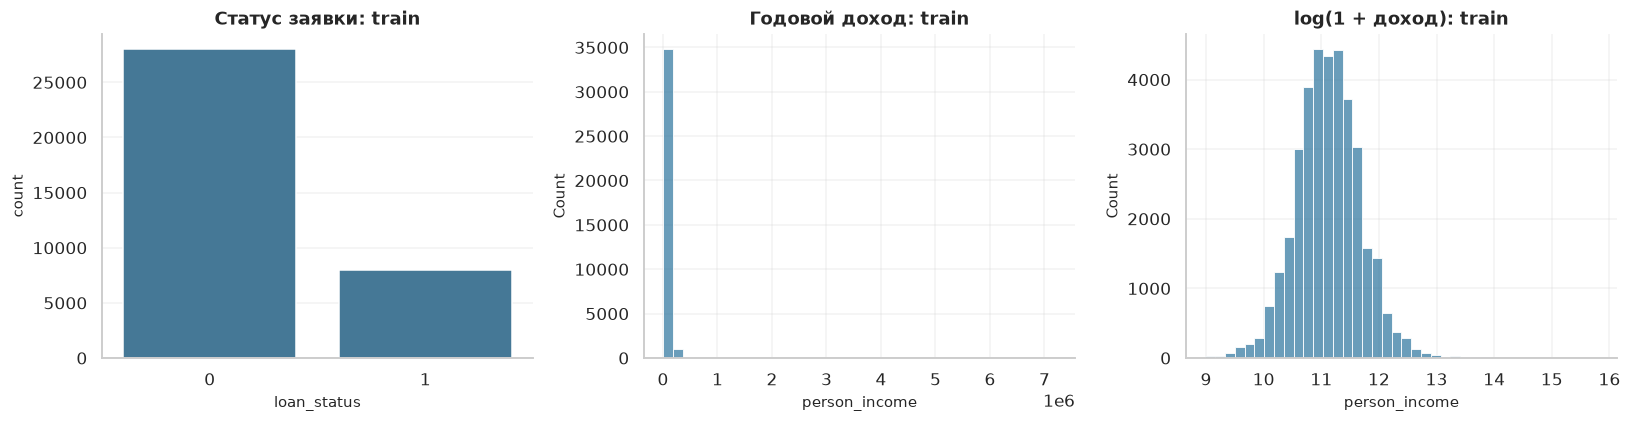

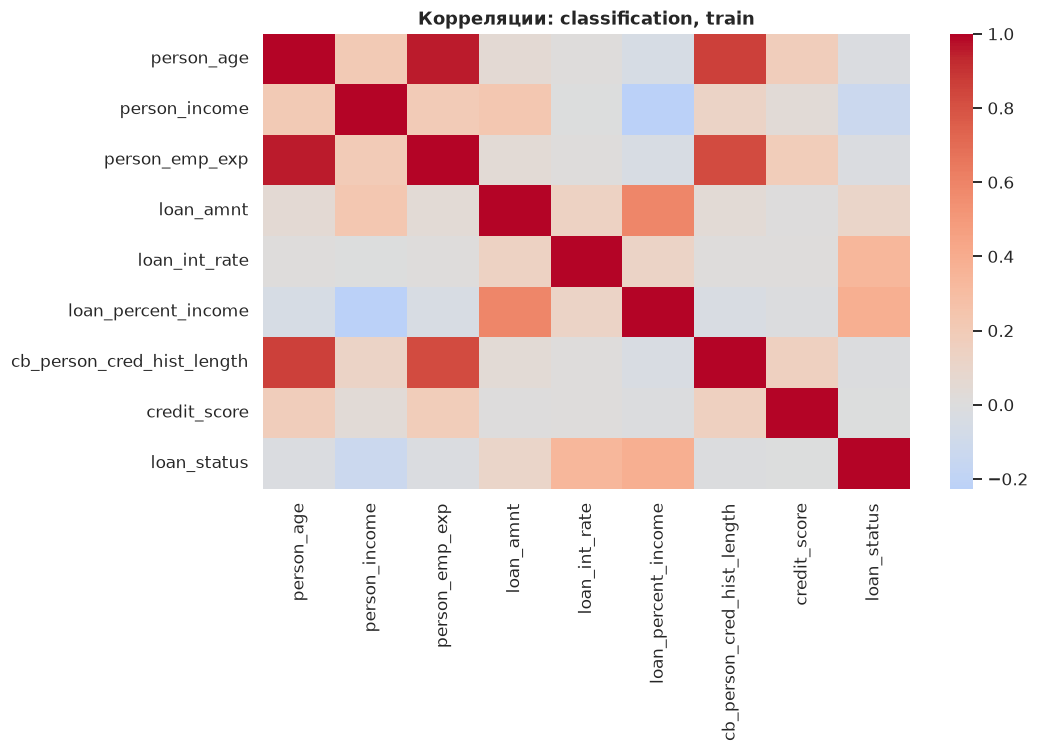

regression Concrete Compressive Strength


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
1,540.0000,0.0000,0.0000,162.0000,2.5000,1055.0000,676.0000,28,61.8874
2,332.5000,142.5000,0.0000,228.0000,0.0000,932.0000,594.0000,270,40.2695
3,332.5000,142.5000,0.0000,228.0000,0.0000,932.0000,594.0000,365,41.0528
4,198.6000,132.4000,0.0000,192.0000,0.0000,978.4000,825.5000,360,44.2961
5,266.0000,114.0000,0.0000,228.0000,0.0000,932.0000,670.0000,90,47.0298


,Тип,Пропуски,Уникальные
cement,float64,0,232
slag,float64,0,158
fly_ash,float64,0,133
water,float64,0,169
superplasticizer,float64,0,126
coarse_aggregate,float64,0,241
fine_aggregate,float64,0,255
age,int64,0,14
strength,float64,0,760


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
count,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000
mean,277.6300,70.2200,55.9300,182.5500,5.8200,974.0500,772.9600,47.5800,34.9700
std,102.5000,87.4000,63.9700,21.4300,5.7100,73.8100,83.1400,67.0100,15.8100
min,108.3000,0.0000,0.0000,121.7500,0.0000,801.0000,594.0000,1.0000,2.3300
25%,192.0000,0.0000,0.0000,166.6100,0.0000,932.0000,716.9500,14.0000,23.6600
50%,266.0000,15.0000,0.0000,185.7000,6.0000,968.0000,780.5800,28.0000,33.7200
75%,339.0000,137.1000,117.5400,193.0000,9.9000,1025.0000,829.7500,56.0000,44.4700
max,540.0000,359.4000,200.1000,246.9000,32.2000,1125.0000,992.6000,365.0000,80.2000


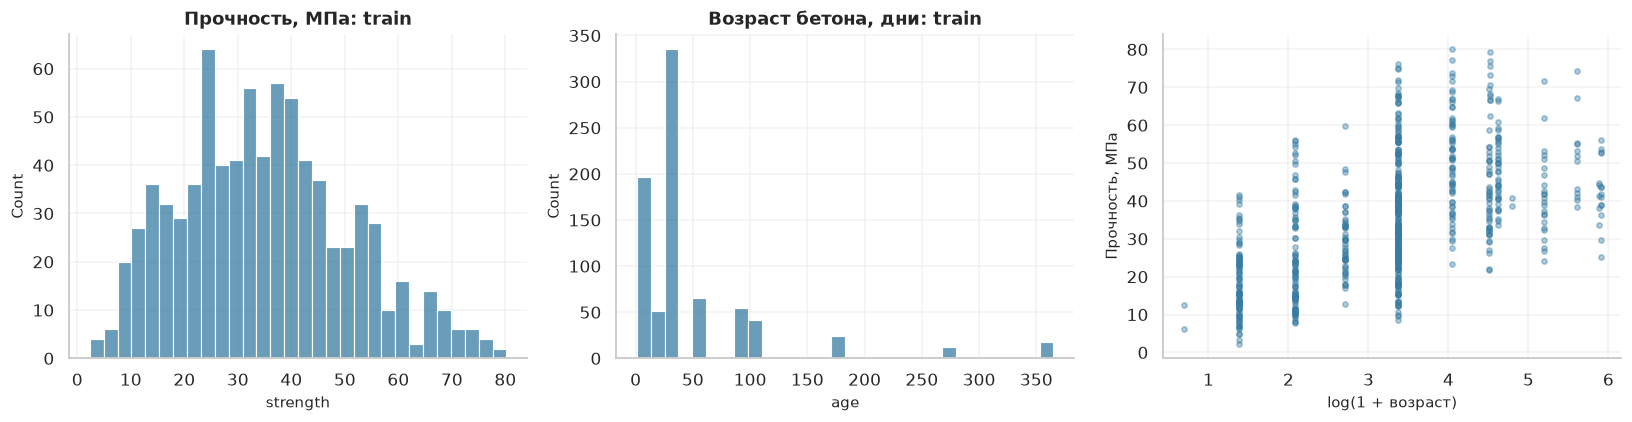

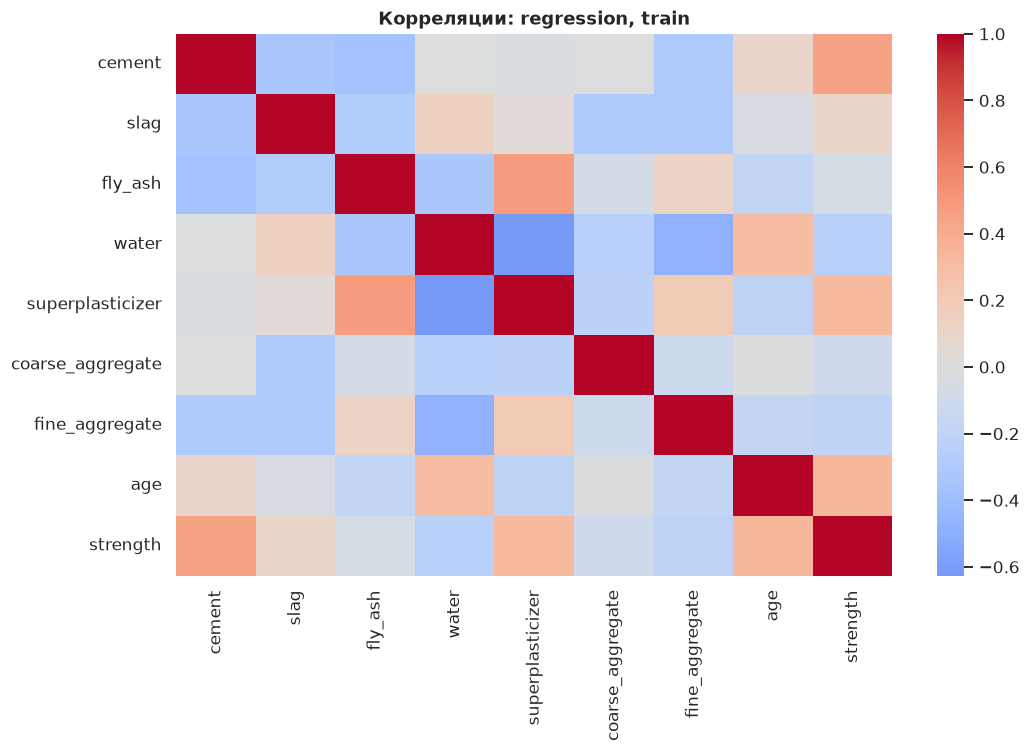

In [4]:
# Test не участвует в EDA и выборе преобразований.
for task, t in tasks.items():
    train = datasets[task].loc[t["train_idx"]]
    print(task, t["spec"]["name"])
    show_table(train.head())
    show_table(pd.DataFrame({"type": train.dtypes.astype(str), "missing": train.isna().sum(),
                          "unique": train.nunique()}))
    show_table(train.describe().round(2))
    if task == "classification":
        show_table(train["loan_status"].value_counts(normalize=True).rename("train_fraction"))
        print("Возраст >100:", int((train.person_age > 100).sum()),
              "; стаж >= возраста:", int((train.person_emp_exp >= train.person_age).sum()))
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        sns.countplot(data=train, x="loan_status", ax=axes[0])
        axes[0].set_title("Статус заявки: train")
        sns.histplot(train["person_income"], bins=40, ax=axes[1])
        axes[1].set_title("Годовой доход: train")
        sns.histplot(np.log1p(train["person_income"]), bins=40, ax=axes[2])
        axes[2].set_title("log(1 + доход): train")
    else:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        sns.histplot(train["strength"], bins=30, ax=axes[0])
        axes[0].set_title("Прочность, МПа: train")
        sns.histplot(train["age"], bins=30, ax=axes[1])
        axes[1].set_title("Возраст бетона, дни: train")
        axes[2].scatter(np.log1p(train["age"]), train["strength"], s=12, alpha=.4)
        axes[2].set(xlabel="log(1 + возраст)", ylabel="Прочность, МПа")
    plt.tight_layout()
    plt.show()
    fig, ax = plt.subplots(figsize=(10, 7))
    sns.heatmap(train.select_dtypes(include="number").corr(), cmap="coolwarm", center=0, ax=ax)
    ax.set_title(f"Корреляции: {task}, train")
    plt.tight_layout()
    plt.show()

### Наблюдения по данным

Класс одобрения составляет около 22,2% заявок, поэтому классы заметно несбалансированы. У дохода выражен правый хвост: большинство значений находятся внизу диапазона, а отдельные большие доходы растягивают шкалу. Это объясняет выбор F1 и гипотезу с log1p.

Для бетона прочность зависит не только от состава, но и от возраста образца. На графике с логарифмической шкалой возраста эту связь удобнее рассматривать. Поэтому далее отдельно проверю log1p возраста и дополнительные признаки состава.

## 2. Исходные модели

Начну с KNN из sklearn: **5 соседей, одинаковые веса, евклидово расстояние**.
Категории закодирую через one-hot, а пропуски заполню медианой или наиболее частым значением.
Масштабирование пока не добавляю — его влияние проверю отдельно.

Также использую простые ориентиры: DummyClassifier всегда выбирает самый частый класс,
а DummyRegressor предсказывает медиану прочности. Это поможет понять, насколько модели
лучше самого простого решения.

Сначала посчитаю качество по CV. Таблицу результатов на test приведу после выбора улучшений.

### Как устроена предобработка

Ниже соберу Pipeline: создание признаков, заполнение пропусков, кодирование категорий
и модель. Этот код показывает все преобразования, которые будут повторяться внутри CV.
Вариант `raw` оставляет исходные масштабы, остальные включают StandardScaler.

In [5]:
# Pipeline для исходного и улучшенных вариантов KNN.
def make_pipeline(X, task, mode="raw", estimator=None):
    categorical = [c for c in CATEGORICAL if c in X]
    numeric = [c for c in X if c not in categorical]
    if mode == "engineered":
        numeric += (["employment_age_ratio", "credit_history_age_ratio"] if task == "classification"
                    else ["binder", "water_binder_ratio", "aggregate_binder_ratio"])
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if mode != "raw":
        num_steps.append(("scale", StandardScaler()))
    transforms = [("numeric", Pipeline(num_steps), numeric)]
    if categorical:
        transforms.append(("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), categorical))
    preprocess = ColumnTransformer(transforms, sparse_threshold=0)
    if estimator is None:
        model_cls = KNeighborsClassifier if task == "classification" else KNeighborsRegressor
        estimator = model_cls(n_neighbors=5, algorithm="brute", n_jobs=1)
    return Pipeline([("features", TaskFeatures(task, mode)), ("preprocess", preprocess), ("model", estimator)])

### Оценка исходных моделей по кросс-валидации

Теперь применю подготовленный Pipeline к трём фолдам train и посчитаю среднее качество исходной модели.

In [6]:
# Фолды фиксированы и одинаковы для всех конфигураций внутри одной задачи.
cv = {"classification": list(StratifiedKFold(3, shuffle=True, random_state=SEED).split(
          tasks["classification"]["X_train"], tasks["classification"]["y_train"])),
      "regression": list(GroupKFold(3).split(tasks["regression"]["X_train"],
          tasks["regression"]["y_train"], tasks["regression"]["groups_train"]))}
for train_fold, valid_fold in cv["regression"]:
    g = tasks["regression"]["groups_train"].to_numpy()
    assert set(g[train_fold]).isdisjoint(g[valid_fold])
scoring = {"classification": "f1", "regression": "neg_mean_absolute_error"}
base_models, hypothesis_records = {}, []
for task, t in tasks.items():
    base_models[task] = make_pipeline(t["X_train"], task, "raw")
    scores = cross_val_score(base_models[task], t["X_train"], t["y_train"],
                             cv=cv[task], scoring=scoring[task], n_jobs=1)
    hypothesis_records.append(dict(task=task, mode="raw", cv_mean=float(scores.mean()),
                                   cv_std=float(scores.std()), folds=scores.tolist()))
    print(task, "baseline CV:", scores, flush=True)

classification baseline CV: [0.56411342 0.56615776 0.57095228]


regression baseline CV: [-7.86501977 -7.38685628 -6.51967195]


## 3. Как можно улучшить KNN

У KNN результат зависит от расстояний между объектами. Поэтому в первую очередь проверю
предобработку, а затем параметры самого алгоритма.

| Гипотеза | Что меняю | Почему это может помочь |
|:--|:--|:--|
| H1 · `scaled` | Стандартизирую числовые признаки | Доход и другие крупные величины не будут подавлять остальные признаки |
| H2 · `log` | Применяю log1p к доходу или возрасту бетона, затем стандартизирую | Уменьшится асимметрия распределений |
| H3 · `engineered` | Добавляю отношения исходных признаков | Они могут лучше описать положение клиента и состав смеси |
| H4 · параметры | Подбираю число соседей, расстояние и веса | Оптимальное соседство может отличаться от исходного |

Для кредитов добавляю стаж/возраст и кредитную историю/возраст.
Для бетона — массу вяжущего `cement + slag + fly_ash`, воду/вяжущее
и заполнители/вяжущее. Новые признаки не используют целевую переменную.

H1 сравню с исходной моделью, H2 — с H1, H3 — с H2. После выбора представления
проверю 12 комбинаций: k ∈ {5, 15, 31}, weights ∈ {uniform, distance}, p ∈ {1, 2}.
Все сравнения провожу на тех же трёх фолдах полного train.

В sklearn MAE при подборе представлена со знаком минус. Поэтому больший CV-score
означает лучший результат и для F1, и для отрицательной MAE.

In [7]:
# Меняем по одному шагу preprocessing при неизменных k=5, weights=uniform, p=2.
for task, t in tasks.items():
    for mode in ["scaled", "log", "engineered"]:
        pipe = make_pipeline(t["X_train"], task, mode)
        scores = cross_val_score(pipe, t["X_train"], t["y_train"],
                                 cv=cv[task], scoring=scoring[task], n_jobs=1)
        hypothesis_records.append(dict(task=task, mode=mode, cv_mean=float(scores.mean()),
                                       cv_std=float(scores.std()), folds=scores.tolist()))
        print(task, mode, "CV mean:", scores.mean(), flush=True)
hypotheses = pd.DataFrame(hypothesis_records)
hypotheses.to_json(RESULTS / "hypotheses.json", orient="records", indent=2)
show_table(hypotheses.drop(columns="folds"))

classification scaled CV mean: 0.658284505469175


classification log CV mean: 0.6758198104641627


classification engineered CV mean: 0.675276596275749


regression scaled CV mean: -7.081122363594666


regression log CV mean: -5.789788759842254


regression engineered CV mean: -5.192995518002198


Задача,Признаки,Среднее CV,Разброс CV
Классификация,raw,0.5671,0.0029
Регрессия,raw,-7.2572,0.5568
Классификация,scaled,0.6583,0.0014
Классификация,log,0.6758,0.0077
Классификация,engineered,0.6753,0.0036
Регрессия,scaled,-7.0811,0.5350
Регрессия,log,-5.7898,0.5168
Регрессия,engineered,-5.1930,0.3751


### Подбор числа соседей, расстояния и весов

Для выбранного набора признаков запущу GridSearchCV.
Сравню средние оценки и их разброс по трём фолдам. Test на этом этапе не использую.

In [8]:
# Подбираем параметры отдельно для классификации и регрессии.
searches, best_modes, selected = {}, {}, {}
for task, t in tasks.items():
    candidates = hypotheses[hypotheses.task == task]
    best_modes[task] = candidates.loc[candidates.cv_mean.idxmax(), "mode"]
    search = GridSearchCV(make_pipeline(t["X_train"], task, best_modes[task]),
                          {"model__n_neighbors": [5, 15, 31],
                           "model__weights": ["uniform", "distance"], "model__p": [1, 2]},
                          scoring=scoring[task], cv=cv[task], n_jobs=1, refit=True,
                          return_train_score=False, error_score="raise")
    search.fit(t["X_train"], t["y_train"])
    searches[task] = search
    selected[task] = {"mode": best_modes[task], "params": search.best_params_,
                      "cv_score": float(search.best_score_)}
    pd.DataFrame(search.cv_results_).to_csv(RESULTS / f"cv_{task}.csv", index=False)
    show_table(pd.DataFrame(search.cv_results_)[["param_model__n_neighbors", "param_model__weights",
            "param_model__p", "mean_test_score", "std_test_score", "rank_test_score"]]
            .sort_values("rank_test_score").head(6))
(RESULTS / "selected.json").write_text(json.dumps(selected, ensure_ascii=False, indent=2));
# Отдельно покажу выбранный вариант для каждой задачи, включая представление признаков.
chosen_rows = []
for task, config in selected.items():
    params = config["params"]
    chosen_rows.append({"Задача": TASK_NAMES[task], "Признаки": config["mode"],
                        "Соседи (k)": params["model__n_neighbors"], "Расстояние (p)": params["model__p"],
                        "Веса": params["model__weights"],
                        "Средний F1 по CV" if task == "classification" else "Средняя MAE по CV, МПа":
                            config["cv_score"] if task == "classification" else -config["cv_score"]})
for row in chosen_rows:
    show_table(pd.DataFrame([row]), "Выбранная конфигурация")


,Соседи (k),Веса,Расстояние (p),Среднее CV,Разброс CV,Место
5,15,distance,1,0.6915,0.0061,1
4,15,uniform,1,0.6895,0.0061,2
7,15,distance,2,0.6890,0.0026,3
6,15,uniform,2,0.6881,0.0022,4
9,31,distance,1,0.6859,0.0031,5
8,31,uniform,1,0.6837,0.0012,6


,Соседи (k),Веса,Расстояние (p),Среднее CV,Разброс CV,Место
3,5,distance,2,-4.5027,0.4289,1
1,5,distance,1,-4.6356,0.3747,2
7,15,distance,2,-5.1879,0.4521,3
2,5,uniform,2,-5.1930,0.3751,4
5,15,distance,1,-5.3906,0.4772,5
0,5,uniform,1,-5.5850,0.4034,6


Задача,Признаки,Соседи (k),Расстояние (p),Веса,Средний F1 по CV
Классификация,log,15,1,distance,0.6915


Задача,Признаки,Соседи (k),Расстояние (p),Веса,"Средняя MAE по CV, МПа"
Регрессия,engineered,5,2,distance,4.5027


### Что дали изменения

Посмотрю, как менялось среднее качество после каждого шага.
Положительная разность ниже означает рост F1 или снижение MAE.
Если разница небольшая по сравнению с разбросом между фолдами,
не буду считать её убедительным улучшением.

In [9]:
# Сравню эффект каждого изменения на тех же CV-фолдах.
hypothesis_rows = []
for task in tasks:
    h = hypotheses[hypotheses.task == task].set_index("mode")
    for name, new, old in [("H1 · масштабирование", "scaled", "raw"),
                           ("H2 · логарифмирование", "log", "scaled"),
                           ("H3 · новые признаки", "engineered", "log")]:
        delta = h.loc[new, "cv_mean"] - h.loc[old, "cv_mean"]
        hypothesis_rows.append({"Задача": TASK_NAMES[task], "Гипотеза": name,
                                "Изменение CV-score": delta,
                                "Результат": "Лучше по среднему CV" if delta > 0 else "Улучшения нет"})
    delta = searches[task].best_score_ - h.loc[best_modes[task], "cv_mean"]
    hypothesis_rows.append({"Задача": TASK_NAMES[task], "Гипотеза": "H4 · параметры",
                            "Изменение CV-score": delta,
                            "Результат": "Лучше по среднему CV" if delta > 0 else "Улучшения нет"})
show_table(pd.DataFrame(hypothesis_rows), "Результаты проверки гипотез")

Задача,Гипотеза,Изменение CV-score,Результат
Классификация,H1 · масштабирование,0.0912,Лучше по среднему CV
Классификация,H2 · логарифмирование,0.0175,Лучше по среднему CV
Классификация,H3 · новые признаки,-0.0005,Улучшения нет
Классификация,H4 · параметры,0.0156,Лучше по среднему CV
Регрессия,H1 · масштабирование,0.1761,Лучше по среднему CV
Регрессия,H2 · логарифмирование,1.2913,Лучше по среднему CV
Регрессия,H3 · новые признаки,0.5968,Лучше по среднему CV
Регрессия,H4 · параметры,0.6903,Лучше по среднему CV


## 4. Своя реализация KNN

Теперь реализую те же действия на NumPy: вычисление расстояний, выбор соседей
и получение прогноза. Для расстояния использую две формулы:

$$d_1(x,z)=\sum_j |x_j-z_j|,\qquad
  d_2(x,z)=\sqrt{\sum_j(x_j-z_j)^2}.$$

В классификации соседи голосуют за класс, в регрессии усредняются их ответы.
При `weights='distance'` вес соседа равен $1/d$.

Если расстояние равно нулю, учитываю только точные совпадения.
При равенстве голосов выбираю первый класс в отсортированном списке.
Если на границе k есть несколько соседей на одном расстоянии, беру более ранний объект train.
У sklearn выбор граничного соседа может отличаться.

Запросы обрабатываю пакетами, чтобы не хранить сразу все расстояния.
Полный поиск всё равно требует $O(n_{test}n_{train}d)$ операций,
поэтому на большом наборе моя реализация может работать заметно дольше.

In [10]:
# Собственная реализация: определения классов выполняются прямо в notebook.
"""KNN на NumPy: собственные расстояния, поиск соседей и агрегация ответов."""

import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
from sklearn.utils.multiclass import check_classification_targets
from sklearn.utils.validation import check_is_fitted, validate_data


class _KNNBase(BaseEstimator):
    def __init__(self, n_neighbors=5, weights="uniform", p=2, batch_size=128):
        self.n_neighbors = n_neighbors
        self.weights = weights
        self.p = p
        self.batch_size = batch_size

    def _fit(self, X, y):
        if not isinstance(self.n_neighbors, (int, np.integer)) or self.n_neighbors < 1:
            raise ValueError("n_neighbors должен быть положительным целым")
        if self.weights not in ("uniform", "distance") or self.p not in (1, 2):
            raise ValueError("Поддерживаются uniform/distance и p=1/2")
        if not isinstance(self.batch_size, (int, np.integer)) or self.batch_size < 1:
            raise ValueError("batch_size должен быть положительным целым")
        X, y = validate_data(self, X, y, dtype=np.float64, ensure_2d=True)
        if y.ndim != 1:
            raise ValueError("Поддерживается одна целевая переменная")
        if self.n_neighbors > len(X):
            raise ValueError("Число соседей превышает размер обучающей выборки")
        # Копии защищают обученную модель от изменения исходных массивов.
        self.X_ = X.copy()
        self.y_ = y.copy()
        return self

    def _neighbors(self, X):
        check_is_fitted(self, ["X_", "y_"])
        X = validate_data(self, X, reset=False, dtype=np.float64)
        for start in range(0, len(X), self.batch_size):
            block = X[start:start + self.batch_size]
            # Накапливаем расстояние по признакам; не создаём тензор (B, N, D).
            distances = np.zeros((len(block), len(self.X_)), dtype=np.float64)
            for column in range(self.n_features_in_):
                delta = block[:, column, None] - self.X_[None, :, column]
                distances += np.abs(delta) if self.p == 1 else delta * delta
            # При совпадении расстояний на границе k выбираем ранний индекс train.
            # Быстрый argpartition дополнен явным разрешением граничных ничьих.
            indices = np.argpartition(distances, self.n_neighbors - 1, axis=1)[:, :self.n_neighbors]
            for row in range(len(block)):
                boundary = distances[row, indices[row]].max()
                closer = np.flatnonzero(distances[row] < boundary)
                equal = np.flatnonzero(distances[row] == boundary)
                indices[row] = np.concatenate((closer, equal[:self.n_neighbors - len(closer)]))
            selected = np.take_along_axis(distances, indices, axis=1)
            if self.p == 2:
                selected = np.sqrt(selected)
            if self.weights == "uniform":
                weights = np.ones_like(selected)
            else:
                zero = selected == 0
                # Если есть точные совпадения, учитываем только их, без деления на 0.
                weights = np.divide(1.0, selected, out=np.zeros_like(selected), where=~zero)
                has_zero = zero.any(axis=1)
                weights[has_zero] = zero[has_zero]
            yield indices, weights


class KNNClassifier(ClassifierMixin, _KNNBase):
    def fit(self, X, y):
        self._fit(X, y)
        check_classification_targets(self.y_)
        self.classes_, self.encoded_y_ = np.unique(self.y_, return_inverse=True)
        return self

    def predict_proba(self, X):
        blocks = []
        for indices, weights in self._neighbors(X):
            labels = self.encoded_y_[indices]
            votes = np.column_stack([
                (weights * (labels == label)).sum(axis=1)
                for label in range(len(self.classes_))
            ])
            blocks.append(votes / weights.sum(axis=1, keepdims=True))
        return np.vstack(blocks)

    def predict(self, X):
        # np.argmax разрешает равенство голосов в пользу первого класса np.unique.
        probabilities = self.predict_proba(X)
        return self.classes_[probabilities.argmax(axis=1)]


class KNNRegressor(RegressorMixin, _KNNBase):
    def fit(self, X, y):
        self._fit(X, y)
        self.y_ = np.asarray(self.y_, dtype=np.float64)
        if not np.isfinite(self.y_).all():
            raise ValueError("y должен содержать конечные числа")
        return self

    def predict(self, X):
        return np.concatenate([
            (self.y_[indices] * weights).sum(axis=1) / weights.sum(axis=1)
            for indices, weights in self._neighbors(X)
        ])

### Обучение и оценка на test

Для каждой задачи обучу пять вариантов: Dummy, исходную и улучшенную модель sklearn,
исходную и улучшенную свою модель. В свою реализацию перенесу те же преобразования
и выбранные параметры. Так можно сравнить именно реализации алгоритма.

Отдельно измерю время обучения и прогноза. Для классификации получу вероятности и классы
за один поиск соседей.

In [11]:
# После фиксации настроек считаем holdout-метрики для каждой задачи на её датасете.
records, fitted, predictions = [], {}, {}
for task, t in tasks.items():
    own_cls = KNNClassifier if task == "classification" else KNNRegressor
    dummy = DummyClassifier(strategy="most_frequent") if task == "classification" else DummyRegressor(strategy="median")
    params = {key.replace("model__", ""): value for key, value in searches[task].best_params_.items()}
    models = {
        "dummy": make_pipeline(t["X_train"], task, "raw", dummy),
        "sklearn_baseline": clone(base_models[task]),
        "sklearn_improved": clone(searches[task].best_estimator_),
        "custom_baseline": make_pipeline(t["X_train"], task, "raw", own_cls()),
        "custom_improved": make_pipeline(t["X_train"], task, best_modes[task], own_cls(**params)),
    }
    feature_set = ",".join(t["X_train"].columns)
    for name, model in models.items():
        started = perf_counter()
        model.fit(t["X_train"], t["y_train"])
        fit_seconds = perf_counter() - started
        started = perf_counter()
        proba = None
        if task == "classification":
            probabilities = model.predict_proba(t["X_test"])
            prediction = model.classes_[probabilities.argmax(axis=1)]
            proba = probabilities[:, list(model.classes_).index(1)]
        else:
            prediction = model.predict(t["X_test"])
        predict_seconds = perf_counter() - started
        scores = evaluate(task, t["y_test"], prediction, proba)
        records.append(dict(lab=1, algorithm="Dummy" if name == "dummy" else "KNN", model=name,
                            implementation="custom" if name.startswith("custom") else "sklearn",
                            stage="dummy" if name == "dummy" else name.split("_")[1], task=task,
                            dataset=t["spec"]["name"], target=targets[task], feature_set=feature_set,
                            dataset_sha=t["spec"]["sha256"], split_sha=t["split_sha"],
                            protocol_id=t["spec"]["protocol_id"],
                            n_train=len(t["X_train"]), n_test=len(t["X_test"]),
                            fit_seconds=fit_seconds, predict_seconds=predict_seconds, **scores))
        fitted[task, name] = model
        predictions[task, name] = (prediction, proba)
metrics = pd.DataFrame(records)
metrics.to_csv(RESULTS / "metrics.csv", index=False)
for task in tasks:
    columns = ["model", "f1", "precision", "recall", "balanced_accuracy", "accuracy", "roc_auc", "average_precision"] if task == "classification" else ["model", "mae", "rmse", "r2"]
    show_table(metrics.loc[metrics.task == task, columns].round(5))

Модель,F1 ↑,Precision,Recall,Balanced accuracy,Accuracy,ROC-AUC,AP
Dummy,0.0000,0.0000,0.0000,0.5000,0.7778,0.5000,0.2222
sklearn · исходная,0.5859,0.6669,0.5225,0.7240,0.8359,0.8147,0.5943
sklearn · улучшенная,0.6960,0.7907,0.6215,0.7873,0.8793,0.9352,0.8303
своя · исходная,0.5859,0.6669,0.5225,0.7240,0.8359,0.8147,0.5943
своя · улучшенная,0.6960,0.7907,0.6215,0.7873,0.8793,0.9352,0.8303


Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
Dummy,14.5233,18.1552,-0.0215
sklearn · исходная,6.6675,9.1470,0.7407
sklearn · улучшенная,4.4187,6.7924,0.8570
своя · исходная,6.6675,9.1470,0.7407
своя · улучшенная,4.4218,6.7929,0.8570


### Где модель ошибается

Для улучшенного классификатора построю матрицу ошибок, ROC и Precision–Recall кривые.
Для регрессии сравню прогноз с фактической прочностью и посмотрю на остатки.
После этих графиков параметры уже не меняю, чтобы не подстраиваться под test.

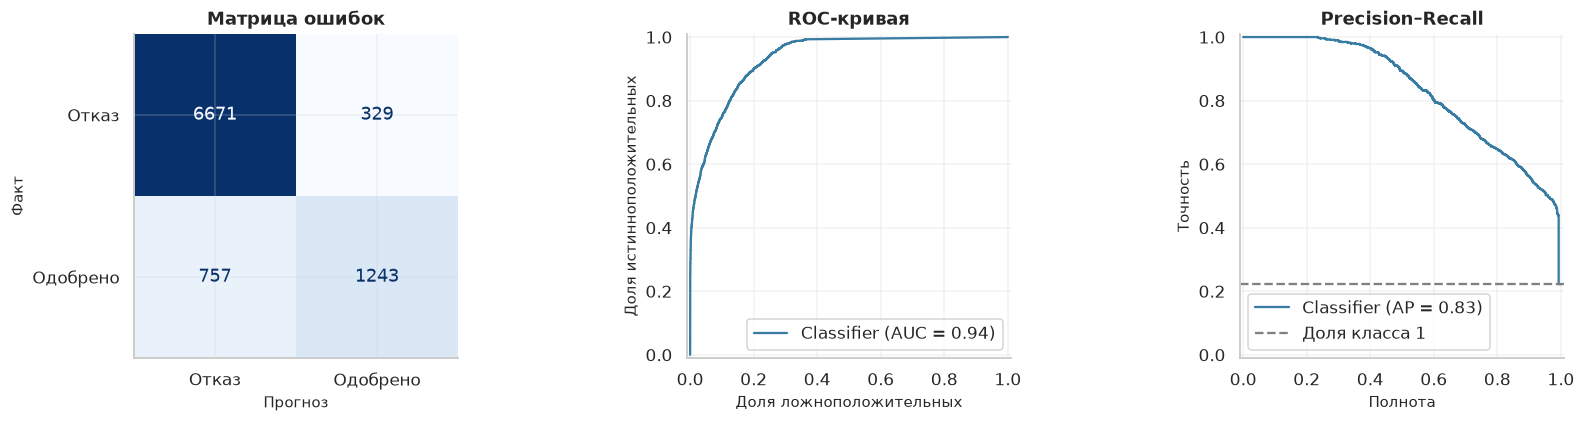

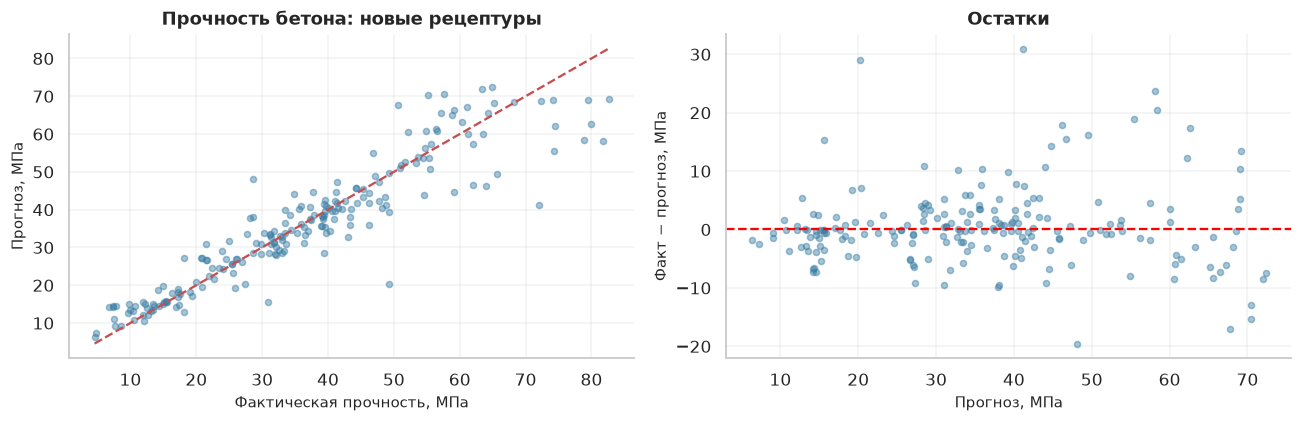

In [12]:
# Результаты не переиспользуются для дополнительного подбора модели.
truth = tasks["classification"]["y_test"]
pred, proba = predictions["classification", "sklearn_improved"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(truth, pred, ax=axes[0], colorbar=False, cmap="Blues", display_labels=["Отказ", "Одобрено"])
RocCurveDisplay.from_predictions(truth, proba, ax=axes[1])
PrecisionRecallDisplay.from_predictions(truth, proba, ax=axes[2])
axes[2].axhline(truth.mean(), color="gray", linestyle="--", label="Доля класса 1")
axes[2].legend()
axes[0].set(title="Матрица ошибок", xlabel="Прогноз", ylabel="Факт")
axes[1].set(title="ROC-кривая", xlabel="Доля ложноположительных", ylabel="Доля истинноположительных")
axes[2].set(title="Precision–Recall", xlabel="Полнота", ylabel="Точность")
plt.tight_layout()
plt.show()
truth_r = tasks["regression"]["y_test"]
pred_r, _ = predictions["regression", "sklearn_improved"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(truth_r, pred_r, alpha=.45, s=16)
axes[0].plot([truth_r.min(), truth_r.max()], [truth_r.min(), truth_r.max()], "r--")
axes[0].set(xlabel="Фактическая прочность, МПа", ylabel="Прогноз, МПа", title="Прочность бетона: новые рецептуры")
axes[1].scatter(pred_r, truth_r - pred_r, alpha=.45, s=16)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Прогноз, МПа", ylabel="Факт − прогноз, МПа", title="Остатки")
plt.tight_layout()
plt.show()

### Что видно по ошибкам

У улучшенного классификатора precision составляет **79,07%**, а recall — **62,15%**. То есть среди предсказанных одобрений большинство верны, но модель находит не все заявки класса 1: остаётся примерно 37,85% пропущенных одобрений. Поэтому одного роста accuracy было бы недостаточно для оценки результата.

В регрессии MAE равна **4,419 МПа**, а RMSE — **6,792 МПа**. Разница между ними показывает, что наряду с небольшими ошибками остаются и более крупные промахи. По графику остатков можно увидеть их отдельно от средней метрики.

## 5. Сравнение результатов

Сначала сравню улучшенные модели с исходными, затем свою реализацию со sklearn
при одинаковых настройках. Для F1 положительная разность — улучшение,
а для MAE лучше отрицательная разность.

In [13]:
# Сравню качество и расхождения ответов между реализациями.
agreements, comparison_rows, agreement_rows = {}, [], []
pairs = [("sklearn_improved", "sklearn_baseline", "Улучшение sklearn"),
         ("custom_baseline", "sklearn_baseline", "Своя и sklearn: исходные"),
         ("custom_improved", "sklearn_improved", "Своя и sklearn: улучшенные"),
         ("custom_improved", "custom_baseline", "Улучшение своей модели")]
for task in tasks:
    m = metrics[metrics.task == task].set_index("model")
    metric = "f1" if task == "classification" else "mae"
    for left, right, label in pairs:
        comparison_rows.append({"Задача": TASK_NAMES[task], "Сравнение": label,
                                "Метрика": "F1" if metric == "f1" else "MAE, МПа",
                                "Разность": m.loc[left, metric] - m.loc[right, metric]})
    agreements[task] = {}
    for stage in ["baseline", "improved"]:
        own = predictions[task, "custom_" + stage][0]
        ref = predictions[task, "sklearn_" + stage][0]
        difference = float(np.mean(own != ref)) if task == "classification" else float(np.mean(np.abs(own - ref)))
        agreements[task][stage] = difference
        agreement_rows.append({"Задача": TASK_NAMES[task], "Вариант": "Исходный" if stage == "baseline" else "Улучшенный",
                               "Расхождение": difference,
                               "Показатель": "Доля разных классов" if task == "classification" else "Среднее |различие прогнозов|, МПа"})
show_table(pd.DataFrame(comparison_rows), "Изменение основных метрик")
show_table(pd.DataFrame(agreement_rows), "Насколько совпали ответы")
show_table(metrics[["task", "model", "fit_seconds", "predict_seconds"]].reset_index(drop=True), "Время работы моделей")
# Покажу конкретные различия регрессионных прогнозов, если они есть.
own = predictions["regression", "custom_improved"][0]
reference = predictions["regression", "sklearn_improved"][0]
different = np.flatnonzero(np.abs(own - reference) > 1e-8)
if len(different):
    show_table(pd.DataFrame({"Исходная строка": tasks["regression"]["X_test"].index[different],
                             "Прогноз sklearn, МПа": reference[different],
                             "Мой прогноз, МПа": own[different]}), "Объекты с различающимися прогнозами")


Задача,Сравнение,Метрика,Разность
Классификация,Улучшение sklearn,F1,0.1100
Классификация,Своя и sklearn: исходные,F1,0.0000
Классификация,Своя и sklearn: улучшенные,F1,0.0000
Классификация,Улучшение своей модели,F1,0.1100
Регрессия,Улучшение sklearn,"MAE, МПа",-2.2488
Регрессия,Своя и sklearn: исходные,"MAE, МПа",0.0000
Регрессия,Своя и sklearn: улучшенные,"MAE, МПа",0.0030
Регрессия,Улучшение своей модели,"MAE, МПа",-2.2457


Задача,Вариант,Расхождение,Показатель
Классификация,Исходный,0.0000,Доля разных классов
Классификация,Улучшенный,0.0000,Доля разных классов
Регрессия,Исходный,0.0000,"Среднее |различие прогнозов|, МПа"
Регрессия,Улучшенный,0.0030,"Среднее |различие прогнозов|, МПа"


Задача,Модель,"Обучение, с","Прогноз, с"
Классификация,Dummy,0.0421,0.0071
Классификация,sklearn · исходная,0.0420,0.8483
Классификация,sklearn · улучшенная,0.0429,3.2308
Классификация,своя · исходная,0.0431,38.6559
Классификация,своя · улучшенная,0.0448,37.7718
Регрессия,Dummy,0.0028,0.0011
Регрессия,sklearn · исходная,0.0025,0.0018
Регрессия,sklearn · улучшенная,0.0042,0.0027
Регрессия,своя · исходная,0.0023,0.0056
Регрессия,своя · улучшенная,0.0037,0.0076


Исходная строка,"Прогноз sklearn, МПа","Мой прогноз, МПа"
60,53.6051,52.9822


### Сохранение результатов

Сохраню метрики, разбиения и выбранные параметры. Эти же данные понадобятся
в следующих работах, чтобы сравнивать алгоритмы на одинаковых объектах.

In [14]:
# Фиксируем параметры, состав данных и независимые разбиения двух задач.
metadata = {"seed": SEED, "cv_folds": 3, "datasets": {}, "selected": selected,
            "selection": "full train CV only; preprocessing then grid; test reporting only",
            "versions": {"python": platform.python_version(), "numpy": np.__version__,
                         "pandas": pd.__version__, "sklearn": sklearn.__version__}}
for task, t in tasks.items():
    metadata["datasets"][task] = {
        "name": t["spec"]["name"], "file": t["spec"]["file"], "target": targets[task],
        "dataset_sha": t["spec"]["sha256"], "split_sha": t["split_sha"],
        "split_file": f"split_{task}.csv", "protocol_id": t["spec"]["protocol_id"],
        "excluded": t["spec"]["excluded"], "features": list(t["X_train"].columns),
        "duplicates_removed": t["duplicates_removed"], "n_train": len(t["X_train"]), "n_test": len(t["X_test"]),
        "holdout": "stratified rows 20%" if task == "classification" else "20% recipe groups, age excluded from group key",
        "cv": "StratifiedKFold(3)" if task == "classification" else "GroupKFold(3), recipe groups",
    }
(RESULTS / "protocol.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
(RESULTS / "agreement.json").write_text(json.dumps(agreements, indent=2))
print("Результаты сохранены.")

Результаты сохранены.


### Итоговые таблицы

Соберу основные показатели отдельно для классификации и регрессии.
На графиках будет видно, насколько изменилось качество после улучшений.

Модель,F1 ↑
sklearn · исходная,0.5859
sklearn · улучшенная,0.6960
своя · исходная,0.5859
своя · улучшенная,0.6960


Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
sklearn · исходная,6.6675,9.1469,0.7407
sklearn · улучшенная,4.4187,6.7924,0.8570
своя · исходная,6.6675,9.1469,0.7407
своя · улучшенная,4.4218,6.7929,0.8570


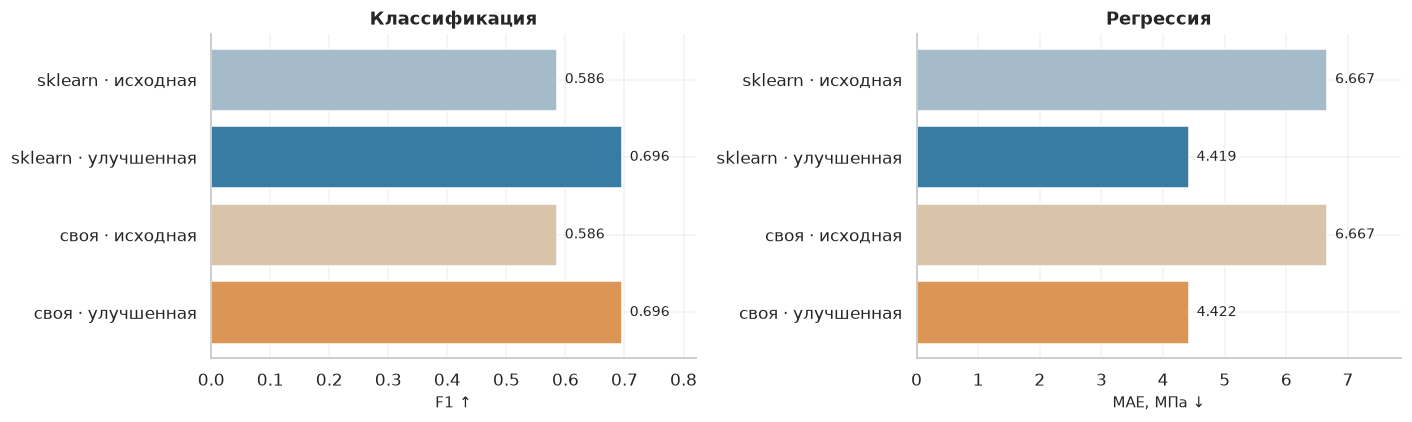

In [15]:
# Компактная сводка обновляется при каждом выполнении notebook.
summary = metrics[metrics.model.isin(["sklearn_baseline", "sklearn_improved", "custom_baseline", "custom_improved"])][
    ["task", "dataset", "model", "f1", "mae", "rmse", "r2"]]
for task in tasks:
    columns = ["model", "f1"] if task == "classification" else ["model", "mae", "rmse", "r2"]
    show_table(summary.loc[summary.task == task, columns].reset_index(drop=True), TASK_NAMES[task])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, task, metric in zip(axes, ["classification", "regression"], ["f1", "mae"]):
    group = summary[summary.task == task]
    labels = [MODEL_NAMES[name] for name in group.model]
    bars = ax.barh(labels, group[metric], color=["#a6bbc9", "#387ca3", "#d9c4aa", "#db9655"])
    ax.bar_label(bars, fmt="%.3f", padding=5, fontsize=9)
    ax.set(title=TASK_NAMES[task], xlabel="F1 ↑" if metric == "f1" else "MAE, МПа ↓")
    ax.set_xlim(0, group[metric].max() * 1.18)
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

### Выводы

Для классификации самым полезным оказалось масштабирование и логарифмирование дохода.
Добавление отношений стажа и кредитной истории к возрасту не улучшило средний F1 по CV.
В итоге выбраны **log-признаки, 15 соседей, манхэттенское расстояние и веса по расстоянию**.
F1 на test вырос с **0,58593 до 0,69597**.

В регрессии помогли логарифм возраста и признаки состава смеси.
Лучший вариант — **engineered, 5 соседей, евклидово расстояние и веса по расстоянию**.
MAE снизилась с **6,667 до 4,419 МПа**, то есть примерно на **33,7%**.
Для сравнения, прогноз одной медианой даёт MAE 14,523 МПа.

Своя классификация дала те же ответы, что и sklearn. В регрессии исходные модели
также совпали, а у улучшенной своей модели MAE составила 4,422 МПа.
Расхождение возникло у одного объекта из 206: два соседа на границе k находятся
на практически одинаковом расстоянии, и из-за округления выбирается другой сосед.

Таким образом, предобработка заметно повлияла на KNN в обеих задачах.
Свою реализацию удалось приблизить к sklearn по качеству, но полный поиск на NumPy
оказался медленнее. Время обучения и прогноза приведено выше.

По четырём сравнениям получилось следующее: улучшения повысили качество sklearn и моей модели;
исходные реализации совпали; после улучшений классификация также совпала,
а MAE своей регрессии отличается от sklearn примерно на 0,003 МПа.
Графики ошибок показывают оставшиеся промахи, поэтому улучшение средней метрики
не означает, что все отдельные прогнозы стали точными.


### Что стоит учитывать

Выводы относятся к двум выбранным наборам и одному разбиению. Повторный подбор
на тех же CV-фолдах может делать оценки оптимистичными, поэтому я отдельно смотрел test.
Кредитные данные синтетические; для бетона разделение исключает одинаковые рецептуры,
но близкие составы всё равно могут оставаться похожими.

**Источники:** [Loan Approval, Kaggle](https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data),
[Concrete Strength, UCI](https://doi.org/10.24432/C5PK67),
[KNN в sklearn](https://scikit-learn.org/stable/modules/neighbors.html).
Подробности о файлах данных и лицензии — в [описании данных](data/README.md).

### Повторный запуск

Для просмотра сохранённых таблиц и графиков выполнять код не нужно.
Для повторения использую Python 3.12 и библиотеки с версиями, выведенными в начале.
Исходные файлы — `lab_1/data/raw/loan_data.csv` и `lab_1/data/raw/Concrete_Data.xls`.
Можно открыть notebook из корня репозитория или папки `lab_1` и выполнить **Run All**.
Все функции загрузки, предобработки, метрик и своя реализация приведены в этом notebook.
